In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
elif not (PROJECT_ROOT / "data").exists() and (PROJECT_ROOT.parent / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "events.csv"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
TABLES_DIR = PROJECT_ROOT / "reports" / "tables"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Data exists:", DATA_PATH.exists())


Project root: /Users/hkkkkjv/Study/memory/4 course/boot/ecommerce-product-analytics
Data exists: True


In [15]:
events = pd.read_csv(DATA_PATH)

required_columns = {"event", "timestamp", "visitorid", "itemid"}
missing_columns = required_columns - set(events.columns)

if missing_columns:
    raise ValueError(f"В датасете отсутствуют обязательные столбцы: {missing_columns}")

events["timestamp"] = pd.to_datetime(
    events["timestamp"],
    unit="ms",
    utc=True,
    errors="coerce"
)

events = events.dropna(subset=["event", "timestamp", "visitorid", "itemid"]).copy()
events["visitorid"] = events["visitorid"].astype("int64")
events["itemid"] = events["itemid"].astype("int64")

events = events.sort_values(["visitorid", "itemid", "timestamp"]).reset_index(drop=True)

print("Shape:", events.shape)
print("Period:", events["timestamp"].min(), "—", events["timestamp"].max())
print("Users:", events["visitorid"].nunique())
print("Items:", events["itemid"].nunique())
print("\nEvent counts:")
display(events["event"].value_counts().to_frame("events"))


Shape: (2756101, 5)
Period: 2015-05-03 03:00:04.384000+00:00 — 2015-09-18 02:59:47.788000+00:00
Users: 1407580
Items: 235061

Event counts:


,events
event,
view,2664312
addtocart,69332
transaction,22457


In [16]:
event_types = ["view", "addtocart", "transaction"]

pair_counts = (
    events[events["event"].isin(event_types)]
    .pivot_table(
        index=["visitorid", "itemid"],
        columns="event",
        values="timestamp",
        aggfunc="size",
        fill_value=0
    )
    .reindex(columns=event_types, fill_value=0)
    .rename(columns={
        "view": "views",
        "addtocart": "addtocarts",
        "transaction": "transactions"
    })
)

first_times = (
    events[events["event"].isin(event_types)]
    .pivot_table(
        index=["visitorid", "itemid"],
        columns="event",
        values="timestamp",
        aggfunc="min"
    )
    .reindex(columns=event_types)
    .rename(columns={
        "view": "first_view",
        "addtocart": "first_addtocart",
        "transaction": "first_transaction"
    })
)

pair_features = pair_counts.join(first_times).reset_index()

for col in ["views", "addtocarts", "transactions"]:
    pair_features[col] = pair_features[col].astype("int32")

pair_features["has_view"] = pair_features["views"] > 0
pair_features["has_addtocart"] = pair_features["addtocarts"] > 0
pair_features["has_transaction"] = pair_features["transactions"] > 0

pair_features["view_before_cart"] = (
    pair_features["first_view"].notna()
    & pair_features["first_addtocart"].notna()
    & (pair_features["first_view"] <= pair_features["first_addtocart"])
)

pair_features["cart_before_transaction"] = (
    pair_features["first_addtocart"].notna()
    & pair_features["first_transaction"].notna()
    & (pair_features["first_addtocart"] <= pair_features["first_transaction"])
)

pair_features["sequential_view_cart"] = pair_features["view_before_cart"]
pair_features["sequential_cart_transaction"] = (
    pair_features["view_before_cart"]
    & pair_features["cart_before_transaction"]
)

pair_features["sequential_full_funnel"] = (
    pair_features["sequential_view_cart"]
    & pair_features["sequential_cart_transaction"]
)

display(pair_features.head())
print("Unique visitor-item pairs:", len(pair_features))


event,visitorid,itemid,views,addtocarts,transactions,first_view,first_addtocart,first_transaction,has_view,has_addtocart,has_transaction,view_before_cart,cart_before_transaction,sequential_view_cart,sequential_cart_transaction,sequential_full_funnel
0,0,67045,1,0,0,2015-09-11 20:55:17.175+00:00,NaT,NaT,True,False,False,False,False,False,False,False
1,0,285930,1,0,0,2015-09-11 20:49:49.439+00:00,NaT,NaT,True,False,False,False,False,False,False,False
2,0,357564,1,0,0,2015-09-11 20:52:39.591+00:00,NaT,NaT,True,False,False,False,False,False,False,False
3,1,72028,1,0,0,2015-08-13 17:46:06.444+00:00,NaT,NaT,True,False,False,False,False,False,False,False
4,2,216305,2,0,0,2015-08-07 18:01:08.920+00:00,NaT,NaT,True,False,False,False,False,False,False,False


Unique visitor-item pairs: 2145179


In [17]:
pair_event_summary = pd.DataFrame({
    "metric": [
        "Visitor-item pairs",
        "Pairs with view",
        "Pairs with add to cart",
        "Pairs with transaction",
        "Pairs with sequential view → cart",
        "Pairs with sequential full funnel"
    ],
    "value": [
        len(pair_features),
        int(pair_features["has_view"].sum()),
        int(pair_features["has_addtocart"].sum()),
        int(pair_features["has_transaction"].sum()),
        int(pair_features["sequential_view_cart"].sum()),
        int(pair_features["sequential_full_funnel"].sum())
    ]
})

display(pair_event_summary)
pair_event_summary.to_csv(TABLES_DIR / "09_pair_event_summary.csv", index=False)


,metric,value
0,Visitor-item pairs,2145179
1,Pairs with view,2132127
2,Pairs with add to cart,62025
3,Pairs with transaction,21270
4,Pairs with sequential view → cart,45395
5,Pairs with sequential full funnel,16502


,stage,pairs,conversion_from_previous,conversion_from_view
0,View,2132127,1.0000,1.0000
1,Add to cart after view,45395,0.0213,0.0213
2,Transaction after cart,16502,0.3635,0.0077


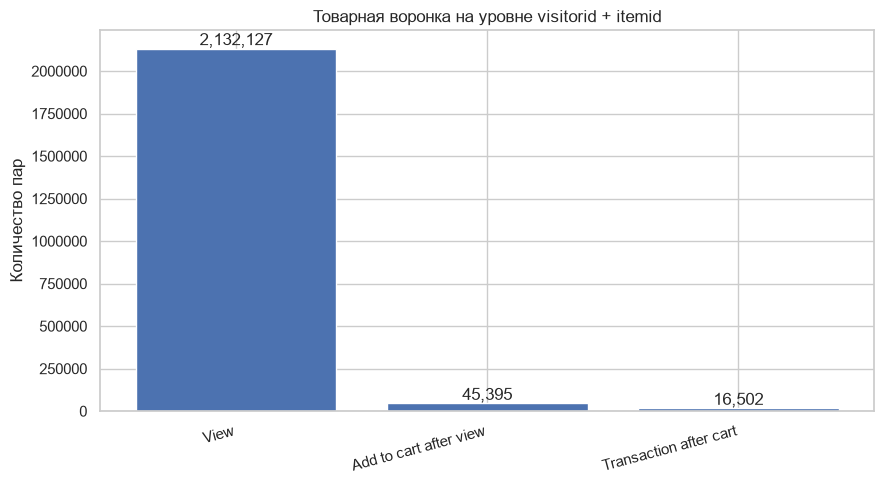

In [18]:
view_pairs = pair_features["has_view"].sum()
cart_after_view_pairs = pair_features["sequential_view_cart"].sum()
transaction_after_cart_pairs = pair_features["sequential_full_funnel"].sum()

item_funnel = pd.DataFrame({
    "stage": ["View", "Add to cart after view", "Transaction after cart"],
    "pairs": [
        int(view_pairs),
        int(cart_after_view_pairs),
        int(transaction_after_cart_pairs)
    ]
})

item_funnel["conversion_from_previous"] = (
    item_funnel["pairs"] / item_funnel["pairs"].shift(1)
)
item_funnel.loc[0, "conversion_from_previous"] = 1.0

item_funnel["conversion_from_view"] = item_funnel["pairs"] / view_pairs

display(item_funnel)
item_funnel.to_csv(TABLES_DIR / "09_item_level_funnel.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(item_funnel["stage"], item_funnel["pairs"])
ax.set_title("Товарная воронка на уровне visitorid + itemid")
ax.set_ylabel("Количество пар")
ax.ticklabel_format(axis="y", style="plain")
plt.xticks(rotation=15, ha="right")
for bar, value in zip(bars, item_funnel["pairs"]):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
            f"{value:,.0f}", ha="center", va="bottom")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "09_item_level_funnel.png", dpi=150, bbox_inches="tight")
plt.show()


In [19]:
item_metrics = (
    pair_features.groupby("itemid")
    .agg(
        visitor_item_pairs=("visitorid", "size"),
        view_pairs=("has_view", "sum"),
        cart_pairs=("sequential_view_cart", "sum"),
        purchase_pairs=("sequential_full_funnel", "sum"),
        total_views=("views", "sum"),
        total_addtocarts=("addtocarts", "sum"),
        total_transactions=("transactions", "sum")
    )
    .reset_index()
)

item_metrics["view_to_cart_rate"] = (
    item_metrics["cart_pairs"] / item_metrics["view_pairs"].replace(0, np.nan)
)
item_metrics["cart_to_purchase_rate"] = (
    item_metrics["purchase_pairs"] / item_metrics["cart_pairs"].replace(0, np.nan)
)
item_metrics["view_to_purchase_rate"] = (
    item_metrics["purchase_pairs"] / item_metrics["view_pairs"].replace(0, np.nan)
)

MIN_VIEW_PAIRS = 100
eligible_items = item_metrics[item_metrics["view_pairs"] >= MIN_VIEW_PAIRS].copy()

print("All items:", len(item_metrics))
print(f"Items with at least {MIN_VIEW_PAIRS} view pairs:", len(eligible_items))

display(
    eligible_items.sort_values("view_pairs", ascending=False).head(10)
)

item_metrics.to_csv(TABLES_DIR / "09_item_level_metrics_all.csv", index=False)
eligible_items.to_csv(TABLES_DIR / "09_item_level_metrics_filtered.csv", index=False)


All items: 235061
Items with at least 100 view pairs: 2554


,itemid,visitor_item_pairs,view_pairs,cart_pairs,purchase_pairs,total_views,total_addtocarts,total_transactions,view_to_cart_rate,cart_to_purchase_rate,view_to_purchase_rate
94720,187946,2912,2911,0,0,3410,2,0,0.0000,NaN,0.0000
2719,5411,2079,2078,8,0,2325,9,0,0.0038,0.0000,0.0000
186716,370653,1577,1577,0,0,1854,0,0,0.0000,NaN,0.0000
232496,461686,1393,1379,251,116,2539,306,133,0.1820,0.4622,0.0841
49024,96924,1359,1359,0,0,1633,0,0,0.0000,NaN,0.0000
110536,219512,1370,1358,29,8,1740,48,12,0.0214,0.2759,0.0059
150148,298009,1342,1342,0,0,1642,0,0,0.0000,NaN,0.0000
169261,335975,1154,1154,0,0,1428,0,0,0.0000,NaN,0.0000
193605,384302,1154,1143,36,13,1528,65,15,0.0315,0.3611,0.0114
76432,151444,1103,1103,0,0,1230,0,0,0.0000,NaN,0.0000


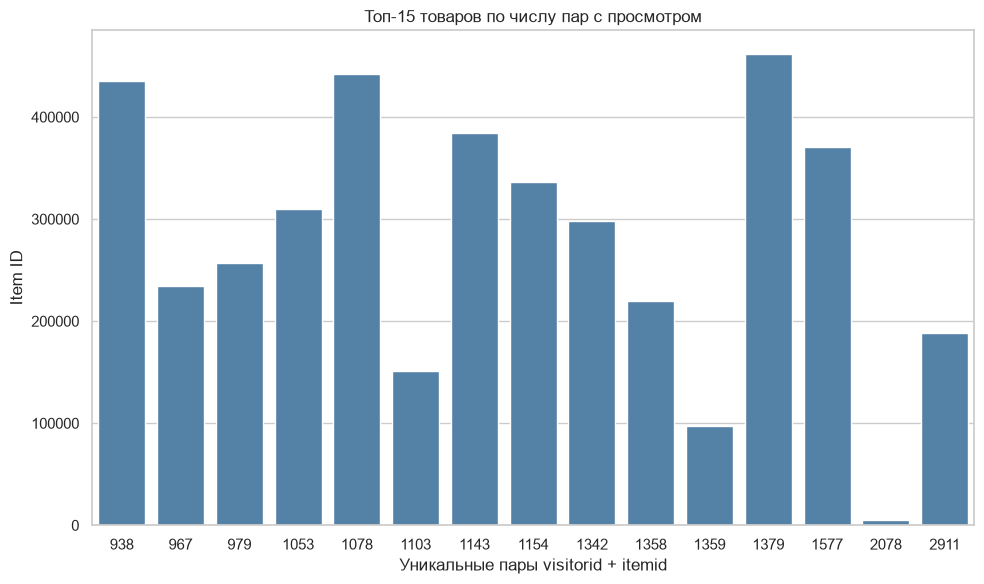

In [20]:
top_viewed_items = (
    eligible_items.sort_values("view_pairs", ascending=False)
    .head(15)
)

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(
    data=top_viewed_items,
    y="itemid",
    x="view_pairs",
    ax=ax,
    color="steelblue"
)
ax.set_title("Топ-15 товаров по числу пар с просмотром")
ax.set_xlabel("Уникальные пары visitorid + itemid")
ax.set_ylabel("Item ID")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "09_top_viewed_items.png", dpi=150, bbox_inches="tight")
plt.show()


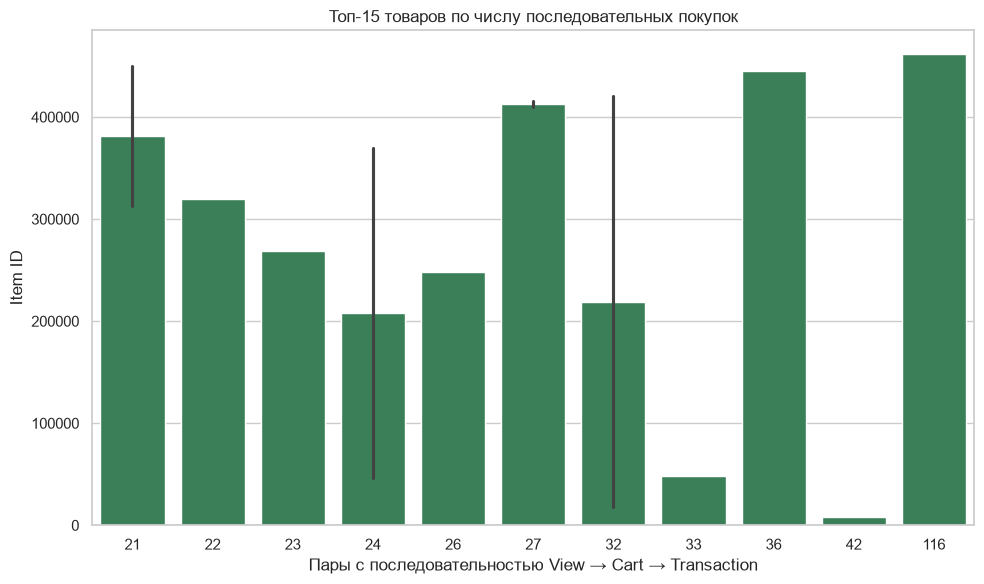

In [21]:
top_purchased_items = (
    eligible_items.sort_values("purchase_pairs", ascending=False)
    .head(15)
)

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(
    data=top_purchased_items,
    y="itemid",
    x="purchase_pairs",
    ax=ax,
    color="seagreen"
)
ax.set_title("Топ-15 товаров по числу последовательных покупок")
ax.set_xlabel("Пары с последовательностью View → Cart → Transaction")
ax.set_ylabel("Item ID")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "09_top_purchased_items.png", dpi=150, bbox_inches="tight")
plt.show()


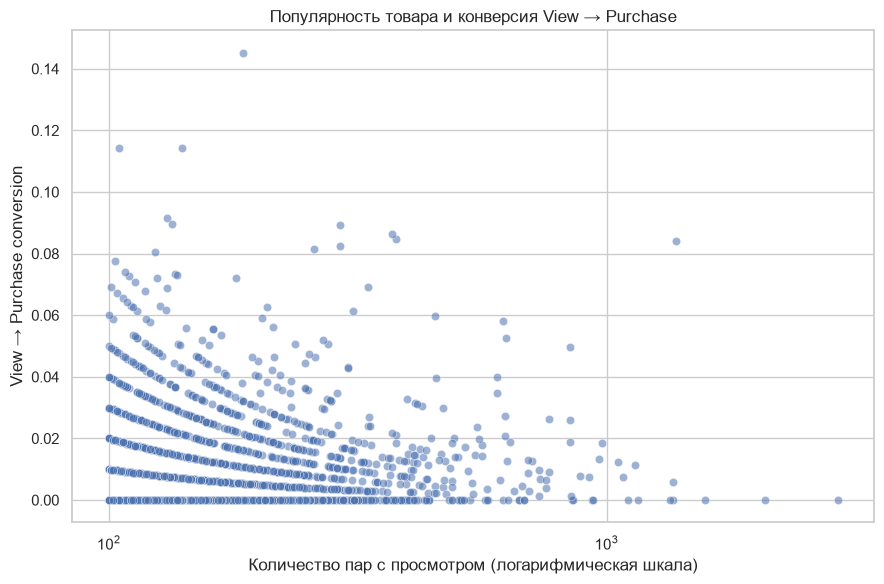

,view_pairs,view_to_purchase_rate
metric,,
view_pairs,1.0000,0.0656
view_to_purchase_rate,0.0656,1.0000


In [22]:
plot_items = eligible_items[
    eligible_items["view_to_purchase_rate"].notna()
].copy()

fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(
    data=plot_items,
    x="view_pairs",
    y="view_to_purchase_rate",
    alpha=0.55,
    ax=ax
)
ax.set_xscale("log")
ax.set_title("Популярность товара и конверсия View → Purchase")
ax.set_xlabel("Количество пар с просмотром (логарифмическая шкала)")
ax.set_ylabel("View → Purchase conversion")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "09_item_popularity_vs_conversion.png", dpi=150, bbox_inches="tight")
plt.show()

display(
    plot_items[["view_pairs", "view_to_purchase_rate"]]
    .corr(method="spearman")
    .rename_axis("metric")
)


,views_per_visitor_item
count,"2,132,127.0000"
mean,1.2496
std,1.1643
min,1.0000
50%,1.0000
75%,1.0000
90%,2.0000
95%,2.0000
99%,5.0000
max,308.0000


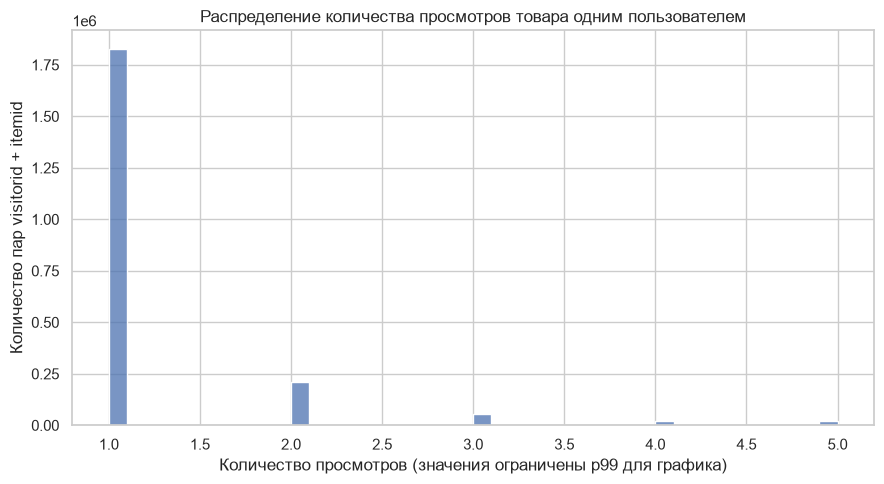

Доля пар с повторными просмотрами: 14.38%


In [23]:
view_intensity = pair_features.loc[
    pair_features["views"] > 0, ["visitorid", "itemid", "views"]
].copy()

view_intensity_summary = (
    view_intensity["views"]
    .describe(percentiles=[0.5, 0.75, 0.90, 0.95, 0.99])
    .to_frame("views_per_visitor_item")
)

display(view_intensity_summary)
view_intensity_summary.to_csv(TABLES_DIR / "09_view_intensity_summary.csv")

fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(
    view_intensity["views"].clip(upper=view_intensity["views"].quantile(0.99)),
    bins=40,
    ax=ax
)
ax.set_title("Распределение количества просмотров товара одним пользователем")
ax.set_xlabel("Количество просмотров (значения ограничены p99 для графика)")
ax.set_ylabel("Количество пар visitorid + itemid")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "09_views_per_visitor_item.png", dpi=150, bbox_inches="tight")
plt.show()

repeat_view_share = (view_intensity["views"] > 1).mean()
print(f"Доля пар с повторными просмотрами: {repeat_view_share:.2%}")


,count,mean,std,min,50%,75%,90%,95%,99%,max
event,,,,,,,,,,
hours_view_to_cart,"16,502.0000",18.7845,113.0840,0.0000,0.0316,0.1757,7.3974,66.3480,487.0141,"3,143.3510"
hours_cart_to_transaction,"16,502.0000",5.6828,60.7262,0.0028,0.0723,0.1854,0.8351,4.2925,129.8117,"2,208.5158"


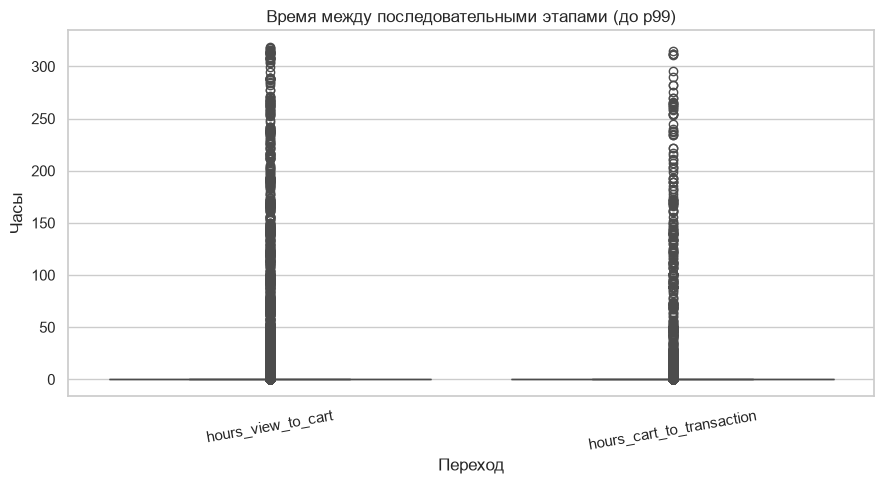

In [24]:
latency = pair_features[
    pair_features["sequential_full_funnel"]
].copy()

latency["hours_view_to_cart"] = (
    latency["first_addtocart"] - latency["first_view"]
).dt.total_seconds() / 3600

latency["hours_cart_to_transaction"] = (
    latency["first_transaction"] - latency["first_addtocart"]
).dt.total_seconds() / 3600

latency = latency[
    (latency["hours_view_to_cart"] >= 0)
    & (latency["hours_cart_to_transaction"] >= 0)
].copy()

latency_summary = latency[
    ["hours_view_to_cart", "hours_cart_to_transaction"]
].describe(percentiles=[0.5, 0.75, 0.90, 0.95, 0.99]).T

display(latency_summary)
latency_summary.to_csv(TABLES_DIR / "09_stage_latency_summary.csv")

latency_long = latency[
    ["hours_view_to_cart", "hours_cart_to_transaction"]
].melt(var_name="transition", value_name="hours")

latency_plot = latency_long[
    latency_long["hours"] <= latency_long["hours"].quantile(0.99)
]

fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=latency_plot, x="transition", y="hours", ax=ax)
ax.set_title("Время между последовательными этапами (до p99)")
ax.set_xlabel("Переход")
ax.set_ylabel("Часы")
ax.tick_params(axis="x", rotation=10)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "09_stage_latency.png", dpi=150, bbox_inches="tight")
plt.show()


,group,purchase_share
0,Top 1%,0.0868
1,Top 5%,0.2152
2,Top 10%,0.3163
3,Top 20%,0.4551


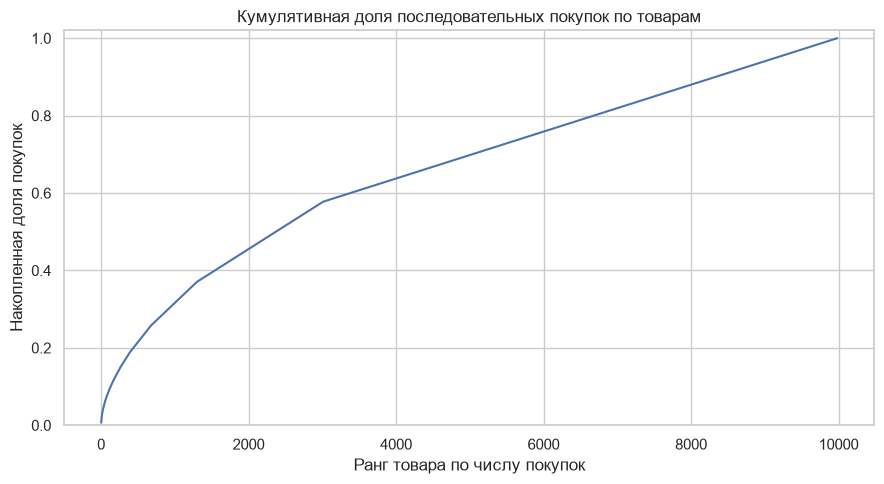

In [25]:
item_purchase_distribution = (
    pair_features.groupby("itemid")["sequential_full_funnel"]
    .sum()
    .rename("purchase_pairs")
    .reset_index()
    .query("purchase_pairs > 0")
    .sort_values("purchase_pairs", ascending=False)
    .reset_index(drop=True)
)

total_purchase_pairs = item_purchase_distribution["purchase_pairs"].sum()
item_purchase_distribution["purchase_share"] = (
    item_purchase_distribution["purchase_pairs"] / total_purchase_pairs
)
item_purchase_distribution["cumulative_purchase_share"] = (
    item_purchase_distribution["purchase_share"].cumsum()
)
item_purchase_distribution["item_rank"] = np.arange(1, len(item_purchase_distribution) + 1)

concentration_summary = pd.DataFrame({
    "group": ["Top 1%", "Top 5%", "Top 10%", "Top 20%"],
    "purchase_share": [
        item_purchase_distribution.head(max(1, int(np.ceil(len(item_purchase_distribution)*p))))["purchase_share"].sum()
        for p in [0.01, 0.05, 0.10, 0.20]
    ]
})

display(concentration_summary)
concentration_summary.to_csv(TABLES_DIR / "09_purchase_concentration.csv", index=False)
item_purchase_distribution.to_csv(TABLES_DIR / "09_item_purchase_distribution.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(
    item_purchase_distribution["item_rank"],
    item_purchase_distribution["cumulative_purchase_share"]
)
ax.set_title("Кумулятивная доля последовательных покупок по товарам")
ax.set_xlabel("Ранг товара по числу покупок")
ax.set_ylabel("Накопленная доля покупок")
ax.set_ylim(0, 1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "09_purchase_concentration_curve.png", dpi=150, bbox_inches="tight")
plt.show()


,diagnostic,pairs
0,Add to cart without any view,12525
1,Transaction without any add to cart,2225
2,Add to cart before first view,4105
3,Transaction before first add to cart,103


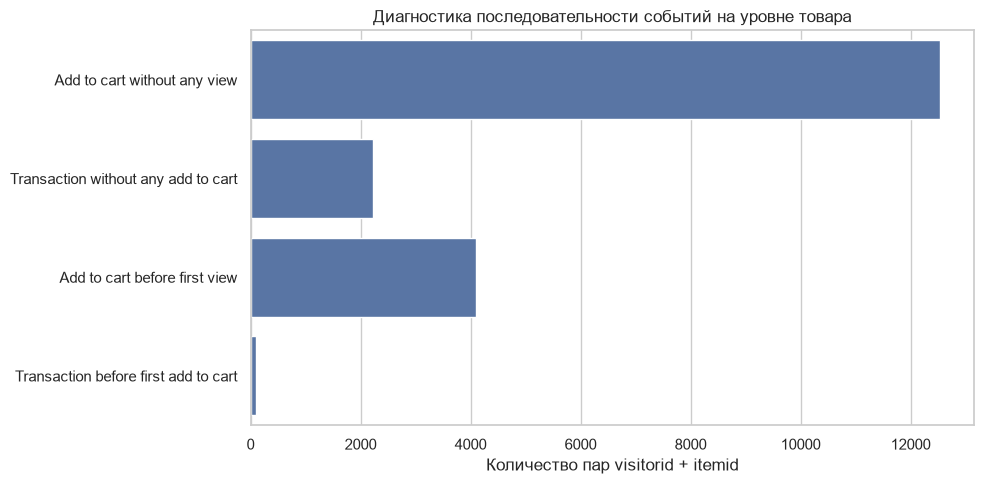

In [26]:
diagnostics = pd.DataFrame({
    "diagnostic": [
        "Add to cart without any view",
        "Transaction without any add to cart",
        "Add to cart before first view",
        "Transaction before first add to cart"
    ],
    "pairs": [
        int((pair_features["has_addtocart"] & ~pair_features["has_view"]).sum()),
        int((pair_features["has_transaction"] & ~pair_features["has_addtocart"]).sum()),
        int((
            pair_features["has_view"]
            & pair_features["has_addtocart"]
            & (pair_features["first_addtocart"] < pair_features["first_view"])
        ).sum()),
        int((
            pair_features["has_addtocart"]
            & pair_features["has_transaction"]
            & (pair_features["first_transaction"] < pair_features["first_addtocart"])
        ).sum())
    ]
})

display(diagnostics)
diagnostics.to_csv(TABLES_DIR / "09_sequence_diagnostics.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=diagnostics, y="diagnostic", x="pairs", ax=ax)
ax.set_title("Диагностика последовательности событий на уровне товара")
ax.set_xlabel("Количество пар visitorid + itemid")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "09_sequence_diagnostics.png", dpi=150, bbox_inches="tight")
plt.show()


In [27]:
summary_metrics = {
    "visitor_item_pairs": len(pair_features),
    "pairs_with_view": int(pair_features["has_view"].sum()),
    "pairs_with_addtocart": int(pair_features["has_addtocart"].sum()),
    "pairs_with_transaction": int(pair_features["has_transaction"].sum()),
    "sequential_view_to_cart_pairs": int(pair_features["sequential_view_cart"].sum()),
    "sequential_full_funnel_pairs": int(pair_features["sequential_full_funnel"].sum()),
    "view_to_cart_conversion": (
        cart_after_view_pairs / view_pairs if view_pairs else np.nan
    ),
    "view_to_purchase_conversion": (
        transaction_after_cart_pairs / view_pairs if view_pairs else np.nan
    ),
    "share_repeat_views": float(repeat_view_share),
    "median_hours_view_to_cart": (
        latency["hours_view_to_cart"].median() if len(latency) else np.nan
    ),
    "median_hours_cart_to_transaction": (
        latency["hours_cart_to_transaction"].median() if len(latency) else np.nan
    )
}

summary_table = pd.DataFrame(
    {"metric": summary_metrics.keys(), "value": summary_metrics.values()}
)

display(summary_table)
summary_table.to_csv(TABLES_DIR / "09_advanced_behavioral_summary.csv", index=False)


,metric,value
0,visitor_item_pairs,"2,145,179.0000"
1,pairs_with_view,"2,132,127.0000"
2,pairs_with_addtocart,"62,025.0000"
3,pairs_with_transaction,"21,270.0000"
4,sequential_view_to_cart_pairs,"45,395.0000"
5,sequential_full_funnel_pairs,"16,502.0000"
6,view_to_cart_conversion,0.0213
7,view_to_purchase_conversion,0.0077
8,share_repeat_views,0.1438
9,median_hours_view_to_cart,0.0316
